Load the Data

In [44]:
import pandas as pd

# Load the 3 CSV files
df1 = pd.read_csv("Premier2223.csv")
df2 = pd.read_csv("Premier2324.csv")
df3 = pd.read_csv("Premier2425.csv")
# List to pass as arg to combine
frames = [df1, df2, df3]
df1['Season'] = '22-23'
df2['Season'] = '23-24'
df3['Season'] = '24-25'
# Combined datafram
df = pd.concat(frames)

df.head()


,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,1XBCH,1XBCD,1XBCA,BFECH,BFECD,BFECA,BFEC>2.5,BFEC<2.5,BFECAHH,BFECAHA
0,E0,05/08/2022,20:00,Crystal Palace,Arsenal,0,2,A,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E0,06/08/2022,12:30,Fulham,Liverpool,2,2,D,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E0,06/08/2022,15:00,Bournemouth,Aston Villa,2,0,H,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,E0,06/08/2022,15:00,Leeds,Wolves,2,1,H,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,E0,06/08/2022,15:00,Newcastle,Nott'm Forest,2,0,H,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [45]:
# Create text file with all columns to see which to keep
with open("df_cols.txt", "w") as f:
    for col in df.columns:
        f.write(f"{col} \n")
    

In [46]:
# Determine features and clean them
features = ['Season', 'HomeTeam', 'AwayTeam', 'FTR']
df_clean = df[features].dropna()

In [49]:
y = df_clean['FTR']
X = df_clean[['Season', 'HomeTeam', 'AwayTeam']]

# one hot encoding 
X_encoded = pd.get_dummies(X, columns=['HomeTeam', 'AwayTeam'])

In [51]:
X_train = X_encoded[X_encoded['Season'] != '24-25'].drop(columns=['Season'])
y_train = y[X_encoded['Season'] != '24-25']

In [52]:
X_test = X_encoded[X_encoded['Season'] == '24-25'].drop(columns=['Season'])
y_test = y[X_encoded['Season'] == '24-25']

In [56]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, n_jobs=-1)

log_reg.fit(X_train, y_train)

LogisticRegression(max_iter=1000, n_jobs=-1)

In [ ]:
from sklearn.metrics import accuracy_score
y_pred = log_reg.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 47.89%


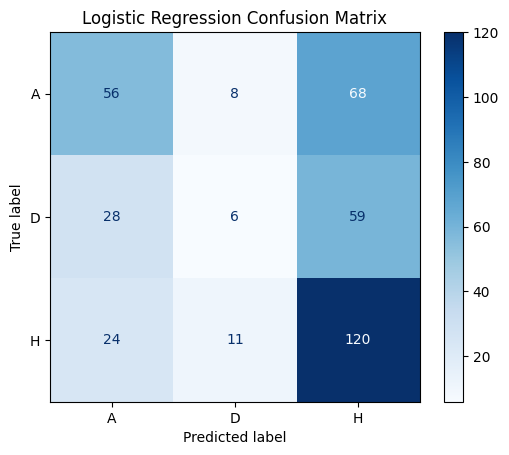

In [61]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=log_reg.classes_)
p = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=log_reg.classes_)

p.plot(cmap=plt.cm.Blues)
plt.title("Logistic Regression Confusion Matrix")
plt.show()